# Topology optimization of a waveguide bend in 3D: a 220 nm silicon guide in oxide

**Question.** The [2D bend tutorial](bend.ipynb) optimizes a 90° turn in a slab
model, where two effective indices stand for the vertical stack. Here the stack is
real: a silicon (Si) core 0.22 µm thick in silica (SiO2), with guides 0.5 µm wide,
the 220 nm silicon-on-insulator (SOI) platform of silicon photonics foundries. In
the 3 µm × 3 µm square where the two guides meet, through the core's thickness,
each point may be silicon or oxide. Which pattern carries the most power at
1.55 µm from the fundamental TE-like mode of one guide into that of the other, and
where does the power it loses go: into the guide's second mode, through the sides
of the box, or out of the plane of the chip?

Silicon's index, 3.48, lies far above the oxide's 1.44, so the guide holds its mode
tightly and can turn within a few microns. On this platform a published 3D
topology optimization of the same bend (Irfan, Kim and Kurt, Sci. Rep. 14 (2024))
reports a loss below 0.1 dB; the question here is what this recipe reaches, and
how far its numbers can be trusted at that level.

**What the run found.** The optimized design, `final`, carries 0.9726 of the
incident power into the output guide's fundamental mode at 1.55 µm, a loss of
0.121 dB, against 0.9562 (0.195 dB) for a circular arc and 0.0438 for a sharp
corner. Of the 0.0270 it neither transmits nor reflects, 0.0041 goes into the
guide's TE1-like mode, 0.0130 leaves the plane of the chip and 0.0099 radiates in
the plane. These three come from sampled-field fluxes whose own check is off by
1.8 × 10⁻² of the delivered power, more than either radiated part ("Trust: where
the remainder goes"). The full stack, a larger box and a finer mesh change |S21|²
by at most 6.6 × 10⁻⁴, and a fit through three meshes puts its mesh error at
5.1 × 10⁻⁴. The paper reports 0.07 dB for a smaller square; `final`'s 0.121 dB
lies above it by far more than the quoted mesh error, 0.002 dB.

The recipe is the 2D tutorial's: pixels ρ → Helmholtz filter → projection → layer
grid → material field → `gfem.solve` → S21, with
[optax](https://optax.readthedocs.io)'s Adam on the pixels. This page explains only
what changes in 3D.

**This page solves nothing.** The optimization and its checks ran once, outside CI
and the docs build, as `tools/bend3d_run.py` (2.5 h on 16 cores and 96 GiB,
with the `mkl` extra). The run wrote a {term}`run record` next to this notebook:
`data/bend3d.json` (provenance, settings and resource observations) and
`data/bend3d.npz` (every solver output). Each number below is computed from the
complex S-matrices and arrays in the record. The code shown is included from the
script that ran, and the first cell stops the page if that script, or the mesh
builder it imports, is no longer the one in the repository.

**Assumptions.**

- Lossless media at their 1.55 µm indices, constant over the band: crystalline Si
  from the tabulated index of H. H. Li, J. Phys. Chem. Ref. Data 9, 561 (1980), at
  293 K, and SiO2 from Malitson, J. Opt. Soc. Am. 55, 1205 (1965), below and above
  the core.
- No substrate: 1.0 µm of oxide above and below the core, then the boundary.
- A second-order absorbing boundary on every outer face, the top and bottom
  included, instead of a PML: 1 µm from the design square in plane and 1.0 µm
  from the core vertically.
- The design is uniform through the core: vertical sidewalls and a full etch. The
  stack and every design are then mirror-symmetric about the core's mid-plane z = 0.
- **Mirror half model.** The fundamental TE-like mode is even about z = 0, so the
  model keeps z ≥ 0 and puts a PMC on z = 0. It solves half the volume for the same
  S-matrix; one re-solve on the full stack checks this.
- Second-order Nédélec elements on a structured tetrahedral mesh, with in-plane
  cells of at most 0.07 µm for the optimization; re-solves at 0.1 µm and 0.06 µm
  check the mesh.

**Conventions.** SI units at the API (the meshes are in µm), time dependence
e^{+iωt}, S-parameters as power waves normalized to 1 W of mode power at each wave
port (see `gfem.conventions`). On the mirror half model the 1 W flows through the
half of the port window above z = 0; the full stack carries the mirror image, so
|S21|² is the same fraction of the incident power in both.

In [1]:
import hashlib
import json
import os
from datetime import datetime
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from contourpy import contour_generator

ROOT, DATA = Path("../.."), Path("data")
record = json.loads((DATA / "bend3d.json").read_text())
with np.load(DATA / "bend3d.npz") as npz:
    out = {key: npz[key] for key in npz.files}
provenance, settings, observed = (
    record[key] for key in ("provenance", "settings", "observations")
)

RERUN = (
    "rerun it with `just bend3d-data` (tools/bend3d_run.py, about 2.7 h and $4.1 "
    "on 16 cores and 96 GiB with the mkl extra) and commit the new data/bend3d.json "
    "and .npz"
)
for script in ("tools/bend3d_run.py", "tools/bend3d_mesh.py"):
    recorded = provenance["sha256"][script]
    current = hashlib.sha256((ROOT / script).read_bytes()).hexdigest()
    if current != recorded:
        raise RuntimeError(
            f"{script} has changed since it wrote the run record (sha256 "
            f"{current[:12]}, recorded {recorded[:12]}), so the record's numbers "
            f"are not this script's: {RERUN}."
        )
if record["profile"] != "full" and os.environ.get("GFEM_BEND3D_ALLOW_SMOKE") != "1":
    raise RuntimeError(
        f"data/bend3d.json is a {record['profile']!r} run, a development check; "
        f"this page publishes the full run: {RERUN}. Set GFEM_BEND3D_ALLOW_SMOKE=1 "
        "to read it anyway."
    )

stages = provenance["stages"]
start = min(datetime.fromisoformat(s["start_utc"]) for s in stages.values())
end = max(datetime.fromisoformat(s["end_utc"]) for s in stages.values())
versions = provenance["versions"]
print(
    f"run record: {record['profile']} profile, run on {start:%Y-%m-%d}, gfem "
    f"{versions['gfem']} at commit {provenance['commit'][:12]}"
)
print(
    f"machine: {provenance['cpu_model']}, {provenance['physical_cores']} cores "
    f"({provenance['threads']} threads), "
    f"{provenance['memory_limit_bytes'] / 2**30:.0f} GiB, {provenance['os']}; "
    f"NGSolve {versions['ngsolve']}, JAX {versions['jax']}, MKL {versions['mkl']} "
    f"(PARDISO {'available' if provenance['pardiso_available'] else 'absent'})"
)
print(
    f"wall time: {(end - start).total_seconds() / 60:.1f} min, from the first "
    "stage's start to the last stage's end; the stages, one process each:"
)
for name, stage in stages.items():
    print(f"  {name}: {stage['command']}")

run record: full profile, run on 2026-10-24, gfem 0.1.0.dev0 at commit 006314c258c1
machine: AMD EPYC 7V73X 64-Core Processor, 16 cores (16 threads), 96 GiB, Debian GNU/Linux 12 (bookworm); NGSolve 6.2.2608, JAX 0.12.0, MKL 2026.2.0 (PARDISO available)
wall time: 150.3 min, from the first stage's start to the last stage's end; the stages, one process each:
  optimize: python tools/bend3d_run.py optimize --out work --profile full
  half: python tools/bend3d_run.py half --out work --profile full
  spectrum: python tools/bend3d_run.py spectrum --out work --profile full
  full: python tools/bend3d_run.py full --out work --profile full
  box: python tools/bend3d_run.py box --out work --profile full
  fine: python tools/bend3d_run.py fine --out work --profile full


## The stack

The box is the 2D tutorial's 5 µm × 5 µm in plane, centred on the bend, now
2.22 µm tall: a Si core 0.22 µm thick at |z| < 0.11 µm, with SiO2 to |z| = 1.11 µm.
The input guide runs along x < -1.5 µm and the output guide along y < -1.5 µm,
both 0.5 µm wide; the design volume is the square |x|, |y| < 1.5 µm through the
core. `tools/bend3d_mesh.py` builds the meshes at run time, with node lines on every
material edge; none is committed.

Each wave port is a window 4.0 µm wide on its guide's end face (|y| < 2.0 µm on
x = -2.5 µm for p1, |x| < 2.0 µm on y = -2.5 µm for p2), through the full height,
whose edges on the absorbing boundary are conducting (`pec_edges`). Mode 1 of each
port, the one the S-matrix uses, is the guide's fundamental TE-like mode. The
model, as the run built it:

```{literalinclude} ../../tools/bend3d_run.py
:pyobject: model
```

Below, the indices: SiO2 recomputed from the cited Sellmeier formula (stored in the
record), and Si, which the run carries as a constant, beside Li's tabulated values
at the ends of the band. Then the port modes' effective indices, and a check on the
model itself: a **straight guide** on the same cross-section, 5 µm long with p2 on
x = +2.5 µm and no bend. Its remainder 1 - |S11|² - |S21|² is the power the model
loses along a guide that should lose none: the part of any remainder below that the
bend does not cause.

In [2]:
um = 1e-6
geometry, cuts, fluxes = (settings[key] for key in ("geometry", "cuts", "fluxes"))
HALF, DESIGN = geometry["box_half_width_um"], geometry["design_half_width_um"]
GUIDE, CORE_HALF = geometry["core_width_um"] / 2, geometry["core_thickness_um"] / 2
Z_TOP = geometry["z_um"][1]  # the top of the stack
PORT = geometry["port_window_half_width_um"]  # half the width of a port window
PITCH = settings["pitch_um"]
H = settings["profile_h_um"]  # in-plane cells: optimization, finer mesh, checks
BAND = settings["spectrum_wavelengths_um"][0], settings["spectrum_wavelengths_um"][-1]
indices = settings["indices"]
N_CLADDING = indices["cladding"]["n"]
# Crystalline Si at 293 K, tabulated by Li (1980), at the band's ends (um).
LI_SI = {1.45: 3.4845, 1.65: 3.4684}
BOX_OXIDE = 2.0  # um, a common buried-oxide thickness under 220 nm silicon


def sellmeier(wavelength_um, terms):
    # n^2 = 1 + sum B l^2 / (l^2 - C^2), with (B, C in um) in terms.
    l2 = wavelength_um**2
    return np.sqrt(1 + sum(b * l2 / (l2 - cc**2) for b, cc in terms))


def mesh_entry(h, *, half=True, kind="bend", box=HALF):
    # The record's entry for a mesh of in-plane cell h (um): stages, tetrahedra, DOF.
    (entry,) = (
        m
        for m in settings["meshes"].values()
        if (m["h_um"], m["half"], m["kind"], m["box_um"]) == (h, half, kind, box)
    )
    return entry


def powers(s):
    # |S21|^2, |S11|^2, |S22|^2 and |S12 - S21| of S[..., to, from] over (p1, p2).
    s = np.asarray(s)
    return (
        np.abs(s[..., 1, 0]) ** 2,
        np.abs(s[..., 0, 0]) ** 2,
        np.abs(s[..., 1, 1]) ** 2,
        np.abs(s[..., 0, 1] - s[..., 1, 0]),
    )


def transmission(key):
    # |S21|^2 of a stored S-matrix: the power out of p2 in its fundamental mode.
    return float(powers(out[key])[0])


def decibels(t):
    # A transmitted fraction as a loss in dB.
    return -10 * np.log10(t)


def report(name, key):
    sent, back = transmission(key), float(powers(out[key])[1])
    print(
        f"{name}: |S21|^2 = {sent:.4f} ({decibels(sent):.3f} dB), "
        f"|S11|^2 = {back:.1e}, remainder = {1 - sent - back:.4f}"
    )
    return sent


for entry in indices.values():
    if entry["sellmeier"] is None:  # a tabulated constant
        print(
            f"{entry['material']}: n = {entry['n']:.4f}, constant ({entry['source']}); "
            f"the table gives {LI_SI[BAND[0]]:.4f} at {BAND[0]} um and "
            f"{LI_SI[BAND[1]]:.4f} at {BAND[1]} um"
        )
        continue
    n = [sellmeier(lam, entry["sellmeier"]) for lam in (BAND[0], 1.55, BAND[1])]
    print(
        f"{entry['material']}: n = {n[1]:.6f} at 1.55 um (the model's "
        f"{entry['n']:.6f}); {n[0]:.4f} at {BAND[0]} um, {n[2]:.4f} at {BAND[1]} um"
    )
n_eff = np.real(out["n_eff"])
optimized_on = mesh_entry(H["h"])
print(
    f"port modes, h = {H['h']} um mirror half model: n_eff = "
    f"{n_eff[0]:.6f} (p1), {n_eff[1]:.6f} (p2), between {N_CLADDING:.6f} and "
    f"{indices['core']['n']:.6f}"
)
decay = settings["wavelength_um"] / (2 * np.pi * np.sqrt(n_eff[0] ** 2 - N_CLADDING**2))
print(
    f"  the mode's field decays by 1/e every {decay:.3f} um into the oxide: "
    "1/gamma, with gamma = k0 sqrt(n_eff^2 - n_SiO2^2)"
)
print(
    f"  {geometry['oxide_above_and_below_um']:g} um of oxide is "
    f"{geometry['oxide_above_and_below_um'] / decay:.1f} decay lengths; across a "
    f"{BOX_OXIDE:g} um buried oxide the field falls to "
    f"exp(-{BOX_OXIDE:g} / {decay:.3f}) = {np.exp(-BOX_OXIDE / decay):.0e}"
)
print(
    f"  each window: |y| or |x| < {PORT:g} um on its end face, |z| < {Z_TOP:g} um "
    "on the full stack"
)
straight = mesh_entry(H["h"], kind="straight")
print(
    f"straight guide, {geometry['straight_guide_length_um']:g} um, "
    f"h = {straight['h_um']} um:"
)
t_straight = report("  straight guide", "s_straight")

Si: n = 3.4757, constant (H. H. Li, J. Phys. Chem. Ref. Data 9, 561 (1980)); the table gives 3.4845 at 1.45 um and 3.4684 at 1.65 um
SiO2: n = 1.444024 at 1.55 um (the model's 1.444024); 1.4452 at 1.45 um, 1.4428 at 1.65 um
port modes, h = 0.07 um mirror half model: n_eff = 2.445064 (p1), 2.445064 (p2), between 1.444024 and 3.475700
  the mode's field decays by 1/e every 0.125 um into the oxide: 1/gamma, with gamma = k0 sqrt(n_eff^2 - n_SiO2^2)
  1 um of oxide is 8.0 decay lengths; across a 2 um buried oxide the field falls to exp(-2 / 0.125) = 1e-07
  each window: |y| or |x| < 2 um on its end face, |z| < 1.11 um on the full stack
straight guide, 5 um, h = 0.07 um:
  straight guide: |S21|^2 = 0.9998 (0.001 dB), |S11|^2 = 1.3e-05, remainder = 0.0002


Both ports solve the same mode, n_eff = 2.445064: between the oxide's 1.444 and
silicon's 3.476. The field falls by 1/e every 0.125 µm into the oxide beside the
core, so the 1.0 µm of oxide above and below holds 8.0 decay lengths, and across a
2 µm buried oxide the field would fall to about 10⁻⁷ of its value at the core: an
estimate from the decay length, not a solve with a substrate. The straight guide
transmits 0.9998, reflects 1.3 × 10⁻⁵ and loses 0.0002 over 5 µm with no bend.

Left, the port plane x = -2.5 µm to scale, white core in black oxide: the p1
window (solid) with its conducting edges, the absorbing boundary around it
(dash-dotted: the rest of the end face, and the top, bottom and sides seen
edge-on), and the mirror plane z = 0 (dotted), above which the mirror half model
lies. Right, the top view of the core layer with the design square at 0.5, where
the optimization starts, p1 solid and p2 dashed.

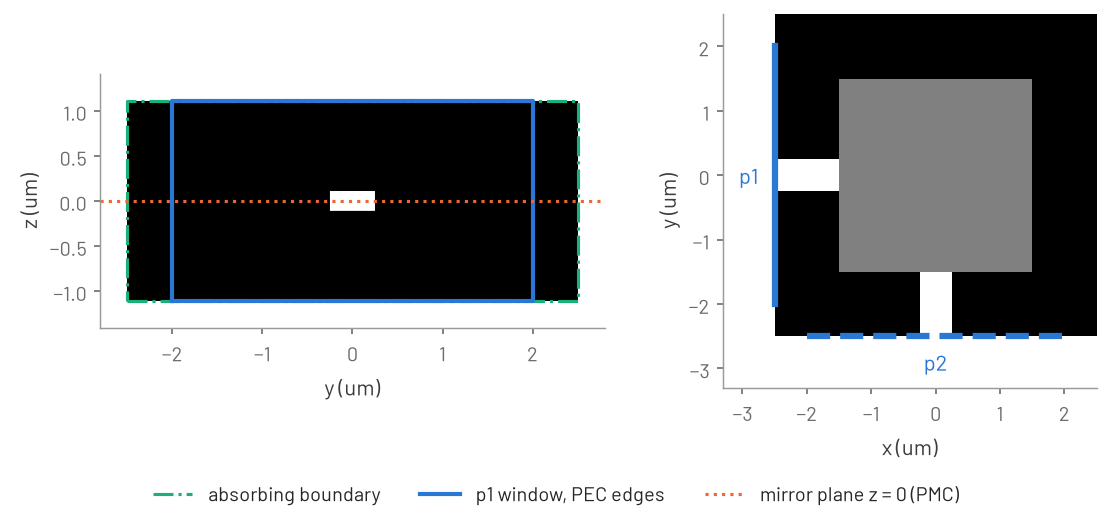

In [3]:
centres = -HALF + (np.arange(round(2 * HALF / PITCH)) + 0.5) * PITCH  # pixel centres
X, Y = np.meshgrid(centres, centres)  # rows y, columns x
ARMS = ((X < -DESIGN) & (np.abs(Y) < GUIDE)) | ((Y < -DESIGN) & (np.abs(X) < GUIDE))
IN_DESIGN = (np.abs(X) < DESIGN) & (np.abs(Y) < DESIGN)
EXTENT = [-HALF, HALF, -HALF, HALF]


def layer_image(density):
    # The core layer of the whole box as a pixel image: the guides around a design.
    image = ARMS.astype(float)
    image[IN_DESIGN] = np.ravel(density)
    return image


step = PITCH / 5  # finer than the pixels: the core is 0.22 um thick
side_y = -HALF + (np.arange(round(2 * HALF / step)) + 0.5) * step
side_z = -Z_TOP + (np.arange(round(2 * Z_TOP / step)) + 0.5) * step
across, up = np.meshgrid(side_y, side_z)  # across the guide, up the stack
section = ((np.abs(across) < GUIDE) & (np.abs(up) < CORE_HALF)).astype(float)

fig, (side, top) = plt.subplots(
    1,
    2,
    figsize=(8, 3.4),
    width_ratios=[2 * HALF, 2 * HALF + 0.8],
    layout="constrained",
)
side.imshow(
    section,
    origin="lower",
    extent=[-HALF, HALF, -Z_TOP, Z_TOP],
    cmap="gray",
    vmin=0,
    vmax=1,
)
square = np.array([[-1, -1], [1, -1], [1, 1], [-1, 1], [-1, -1]])
side.plot(*(square * [HALF, Z_TOP]).T, color="C2", ls="-.", label="absorbing boundary")
side.plot(
    *(square * [PORT, Z_TOP]).T, color="C0", ls="-", lw=2, label="p1 window, PEC edges"
)
side.axhline(0, color="C1", ls=":", lw=1.5, label="mirror plane z = 0 (PMC)")
side.set_xlim(-HALF - 0.3, HALF + 0.3)  # the boundary lines clear of the image edge
side.set_ylim(-Z_TOP - 0.3, Z_TOP + 0.3)
side.set_xlabel("y (um)")
side.set_ylabel("z (um)")

top.imshow(
    layer_image(out["rho_start"]),
    origin="lower",
    extent=EXTENT,
    cmap="gray",
    vmin=0,
    vmax=1,
)
for port, (lo, hi), style in (
    ("p1", ([-HALF, -PORT], [-HALF, PORT]), "-"),
    ("p2", ([-PORT, -HALF], [PORT, -HALF]), "--"),
):
    top.plot([lo[0], hi[0]], [lo[1], hi[1]], color="C0", ls=style, lw=3)
    middle = (np.array(lo) + np.array(hi)) / 2  # the label sits outside the image
    top.text(*middle * (1 + 0.4 / HALF), port, color="C0", ha="center", va="center")
top.set_xlim(-HALF - 0.8, HALF)
top.set_ylim(-HALF - 0.8, HALF)
top.set_xlabel("x (um)")
top.set_ylabel("y (um)")
fig.legend(loc="outside lower center", ncols=3);

Two hand-drawn bends set the scale before any optimization, the 2D tutorial's
rebuilt for 0.5 µm guides. The **arc design** is a quarter ring 0.5 µm wide, of
radius 1.5 µm about the corner (-1.5, -1.5) µm; the **corner design** extends both
guides until they meet in a sharp L. Their pixels hold the area fraction of core.
Each is one driven solve at 1.55 µm with both ports excited, on the mirror half
model.

The media are lossless, so the remainder 1 - |S11|² - |S21|² is power that leaves
port 1's mode for neither port's fundamental mode. Here it has three destinations:

- **The TE1-like mode.** The 0.5 µm guide carries a second TE-like mode, odd across
  its width. Port mode problems solved over the guide width, outside this run, put
  its index near 1.493, just above the oxide's, and its cutoff width near 0.44 µm.
  The arms are symmetric across their width, so only the design square converts
  power into it; the wave ports solve the fundamental mode only, so that power
  counts in the remainder.
- **Radiation in plane**, through the side faces.
- **Radiation out of plane**, through the top and bottom.

TE-like and TM-like modes do not couple in a stack and design symmetric about
z = 0, so the guide's TM-like mode takes no power. "Trust: where the remainder
goes" measures the three parts for `final`, and the TE1-like part for the arc.

In [4]:
t_arc = report("arc design", "s_arc")
t_corner = report("corner design", "s_corner")

arc design: |S21|^2 = 0.9562 (0.195 dB), |S11|^2 = 3.7e-06, remainder = 0.0438
corner design: |S21|^2 = 0.0438 (13.583 dB), |S11|^2 = 9.5e-02, remainder = 0.8608


The arc keeps 0.9562 of the power in the guide (0.195 dB) and the corner 0.0438.
The arc reflects almost nothing, |S11|² = 3.7 × 10⁻⁶, so its remainder, 0.0438,
leaves the guide's fundamental mode inside the turn: about half of it into the
TE1-like mode, as "Trust: where the remainder goes" measures. The corner reflects
9.5 × 10⁻² and loses 0.8608 to the remainder: at a sharp turn most of the power
leaves the guide. A silicon guide 0.5 µm wide already turns well at a 1.5 µm
radius, so the arc sets a high bar. These are the numbers the optimization has to
beat.

## From pixels to a material

The chain is the 2D tutorial's (see its section of the same name): 60 × 60 pixels
of 0.05 µm over the design square, mirrored about y = x, a Helmholtz filter, and a
projection of sharpness β. Each mesh element takes the pixel image at its centroid,
and the design is uniform through the core. A pixel value of 0 is SiO2 and 1 is Si,
with ε_r linear in between.

The filter's radius is 0.2 µm, against the 2D tutorial's 0.3 µm: light in silicon
has a shorter wavelength than in the slab model's core, by the ratio of their
indices, 2.25 / 3.48, which takes 0.3 µm to about 0.2 µm. The radius sets a typical
feature size, not a minimum width (Limits).

```{literalinclude} ../../tools/bend3d_run.py
:pyobject: layer_grid
```

```{literalinclude} ../../tools/bend3d_run.py
:pyobject: density_filter
```

```{literalinclude} ../../tools/bend3d_run.py
:pyobject: filtered
```

```{literalinclude} ../../tools/bend3d_run.py
:pyobject: physical
```

```{literalinclude} ../../tools/bend3d_run.py
:pyobject: material
```

## Optimize

The objective is the 2D one, 1 - |S21|² at 1.55 µm, from one driven solve with both
ports excited. `has_aux` returns |S21|² and the core fraction with the gradient:

```{literalinclude} ../../tools/bend3d_run.py
:pyobject: missed_power
```

What changes is the solver. The mirror half model at h = 0.07 µm (its size is
printed below) is solved by the sparse direct solver: PARDISO, from the `mkl`
extra. A gradient reuses the forward factorization in the backward pass when
the retained memory budget holds it. The run sets that budget to 10 GiB, enough for
one solve's factorization on this mesh; the default is half of the machine's
memory. Every stage of the run, the re-solves below included, uses these options:

```{literalinclude} ../../tools/bend3d_run.py
:start-at: The solver of every stage
:end-at: DIRECT = gfem.SolverOptions
```

The loop is the 2D tutorial's (`optimize` in the script): Adam with step 0.1 on the
raw pixels, clipped to [0, 1], from a uniform 0.5; β doubles from 1 to 32 every 7
steps, 42 iterations in all. Below, the schedule as recorded and the time each
iteration took on the run's machine: observations of that machine, not benchmarks.

In [5]:
schedule = settings["schedule"]
t_history, core_history = out["t_history"], out["core_history"]
seconds = out["seconds_history"]
n_steps, steps_per_beta = schedule["iterations"], schedule["steps_per_beta"]
print(
    f"{n_steps} iterations: beta = {', '.join(f'{b:g}' for b in schedule['betas'])}, "
    f"{steps_per_beta} each; {schedule['optimizer']}({schedule['learning_rate']}), "
    f"clipped to {schedule['clip']}, from {schedule['start']}"
)
print(
    f"mesh: h = {optimized_on['h_um']} um, mirror half model, "
    f"{optimized_on['tets']:,} tetrahedra, {optimized_on['dof']:,} DOF at order "
    f"{settings['order']}"
)
print(
    f"one solve and its gradient: median {np.median(seconds[1:]):.1f} s, "
    f"{seconds[1:].min():.1f} to {seconds[1:].max():.1f} s over iterations 1 to "
    f"{n_steps - 1}; iteration 0, with the JIT compilation, {seconds[0]:.1f} s"
)
optimize_stage = observed["optimize"]
print(
    f"optimize stage: {optimize_stage['wall_s'] / 60:.1f} min, peak memory "
    f"{optimize_stage['peak_rss_bytes'] / 2**30:.1f} GiB"
)

42 iterations: beta = 1, 2, 4, 8, 16, 32, 7 each; optax.adam(0.1), clipped to [0.0, 1.0], from 0.5
mesh: h = 0.07 um, mirror half model, 381,216 tetrahedra, 2,489,174 DOF at order 2
one solve and its gradient: median 146.8 s, 135.6 to 157.4 s over iterations 1 to 41; iteration 0, with the JIT compilation, 141.0 s
optimize stage: 102.7 min, peak memory 68.3 GiB


|S21|² and the core fraction per iteration. The dotted black line is the arc
design's |S21|²; the thin grey lines mark where β doubles. |S21|² climbs
fastest at β = 1, in the first seven iterations, then by smaller steps. It is
0.899 at iteration 14 (snapshots below), first passes the arc's at iteration 27,
at β = 8, drops just below it when β doubles to 16, and stays above it from
iteration 30 on, ending at 0.973. The last few hundredths come slowly: the arc is
already a good bend. The core fraction rises from 0.5 and settles near 0.6.

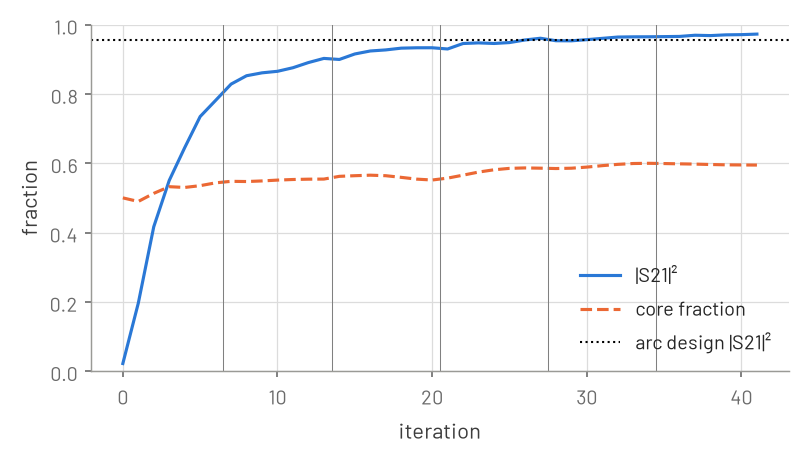

In [6]:
fig, ax = plt.subplots(figsize=(6, 3))
ax.plot(t_history, label="|S21|²")
ax.plot(core_history, label="core fraction")
ax.axhline(t_arc, color="k", ls=":", lw=1, label="arc design |S21|²")
for k in range(steps_per_beta, n_steps, steps_per_beta):
    ax.axvline(k - 0.5, color="gray", lw=0.5)
ax.set_ylim(0, 1)
ax.set_xlabel("iteration")
ax.set_ylabel("fraction")
ax.legend(loc="lower right");

## The design

The physical density at four evenly spaced iterations, white Si and black SiO2,
with each iteration's |S21|². By iteration 14 the design holds
a curved silicon guide along the inner side of the bend, close to the arc's path,
with curved strips outside it, roughly concentric with it. Over the later
iterations the strips break into segments and islands, touching the guide in
places, and a small island forms inside the bend near its inner corner. By
iteration 41 (β = 32) the design is nearly binary.

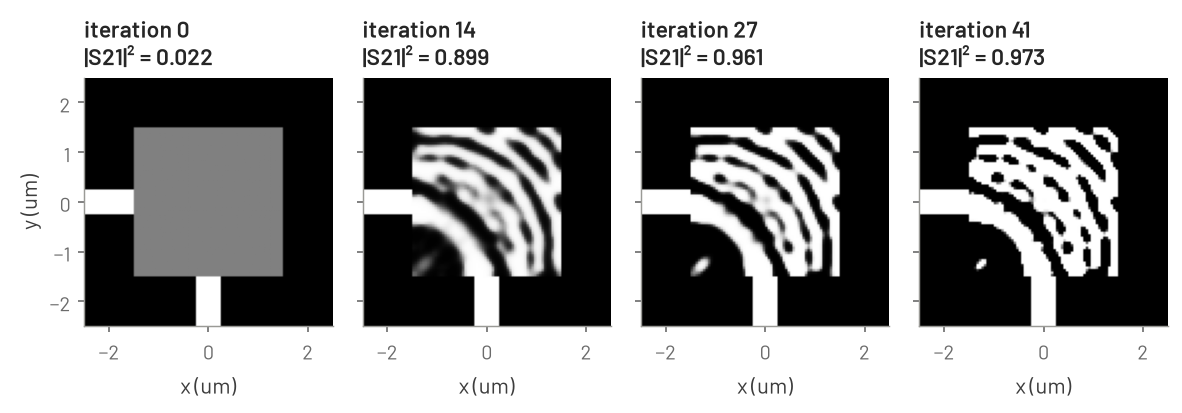

In [7]:
snapshot_at = out["snapshot_iterations"]
fig, axes = plt.subplots(1, 4, figsize=(8, 2.6), sharey=True)
for ax, k, density in zip(axes, snapshot_at, out["snapshots"], strict=True):
    ax.imshow(
        layer_image(density), origin="lower", extent=EXTENT, cmap="gray", vmin=0, vmax=1
    )
    ax.set_title(f"iteration {k}\n|S21|² = {t_history[k]:.3f}")
    ax.set_xlabel("x (um)")
axes[0].set_ylabel("y (um)")
fig.tight_layout();

The design we evaluate is `final`: the last physical density (after the last Adam
step, at the last β) thresholded at 0.5, a two-material image. Every number after
this is about `final`, except the eroded and dilated variants below. Here, |S21|²
of the last iterate next to that of `final`, and the share of the last density's
pixels already within 0.05 of 0 or 1.

In [8]:
last, final = out["last"], out["final"]
t_last, t_final = transmission("s_last"), transmission("s_final")
print(f"iteration {n_steps - 1}: |S21|^2 = {t_history[-1]:.4f} (before its Adam step)")
print(f"last density, beta = {schedule['betas'][-1]:g}: |S21|^2 = {t_last:.4f}")
print(
    f"final: |S21|^2 = {t_final:.4f}, thresholded at {settings['threshold']}, "
    f"{final.mean():.1%} core"
)
binary = np.mean((last < 0.05) | (last > 0.95))
print(f"{binary:.1%} of the last density's pixels lie within 0.05 of 0 or 1")

iteration 41: |S21|^2 = 0.9727 (before its Adam step)
last density, beta = 32: |S21|^2 = 0.9744
final: |S21|^2 = 0.9726, thresholded at 0.5, 59.3% core
94.0% of the last density's pixels lie within 0.05 of 0 or 1


Thresholding costs little: the last density transmits 0.9744 and `final`
0.9726, since 94.0 % of the last density's pixels were already within 0.05 of 0
or 1. `final` is 59.3 % silicon.

`final` in 3D, seen from above the output guide's side: the oxide see-through, the
core (tan, translucent) with `final`'s core pixels as blocks through the 0.22 µm
core, and two field cuts on one grey scale: |E| on the core mid-plane z = 0 and
across the input guide, between port 1 and the design square, through the full
height. Port p1 is fed with 1 W incident; |E| is scaled to its peak on the input
guide in the mid-plane. The fields come from the mirror half model and are mirrored
about z = 0 for the view, where the TE-like field is even.

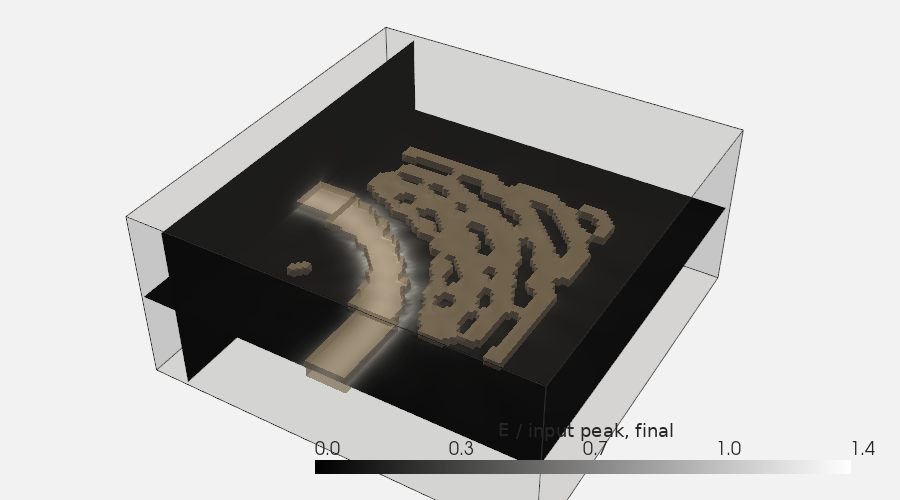

In [9]:
import pyvista as pv

pv.set_jupyter_backend("static")
VIEW = (0.6, -1, 0.9)  # the camera's direction: above, on the output guide's side
cut_x, cut_y, cut_z = (out[key] / um for key in ("cut_x", "cut_y", "cut_z"))
input_peak = {  # |E| peak in the input guide's part of the mid-plane cut
    name: out[f"cut_top_{name}"][:, cut_x < -DESIGN].astype(float).max()
    for name in ("final", "arc")
}


def mirrored(cut):
    # A cut over z >= 0 (columns z) as the full height of the stack.
    return np.concatenate([cut[:, ::-1], cut], axis=1).astype(float)


def plane(u, v, values, place):
    # A sampled cut as a surface: values (len(u), len(v)) at points place(U, V).
    U, V = np.meshgrid(u, v, indexing="ij")
    surface = pv.StructuredGrid(*place(U, V))
    surface.point_data["|E|"] = values.ravel(order="F")
    return surface


every = 2  # every other sample: 100 x 100 points on the mid-plane
heights_full = np.concatenate([-cut_z[::-1], cut_z])
surfaces = [
    plane(
        cut_x[::every],
        cut_y[::every],
        (out["cut_top_final"].astype(float).T / input_peak["final"])[::every, ::every],
        lambda U, V: (U, V, np.zeros_like(U)),
    ),
    plane(
        cut_y[::every],
        heights_full[::every],
        mirrored(out["cut_in_final"])[::every, ::every] / input_peak["final"],
        lambda U, V: (np.full_like(U, cuts["cut_in_x_um"]), U, V),
    ),
]
blocks = pv.ImageData(
    dimensions=(final.shape[1] + 1, final.shape[0] + 1, 2),
    spacing=(PITCH, PITCH, 2 * CORE_HALF),
    origin=(-DESIGN, -DESIGN, -CORE_HALF),
)
blocks.cell_data["core"] = final.ravel().astype(float)  # x fastest: rows are y
core = [
    pv.Box((-HALF, -DESIGN, -GUIDE, GUIDE, -CORE_HALF, CORE_HALF)),
    pv.Box((-GUIDE, GUIDE, -HALF, -DESIGN, -CORE_HALF, CORE_HALF)),
    blocks.threshold(0.5, scalars="core"),
]
oxide = pv.Box((-HALF, HALF, -HALF, HALF, -Z_TOP, Z_TOP))
peak = max(c["|E|"].max() for c in surfaces)

view = pv.Plotter(window_size=(900, 500))
view.add_mesh(oxide, color="lightgrey", opacity=0.15)
view.add_mesh(oxide.outline(), color="black")
for part in core:
    view.add_mesh(part, color="tan", opacity=0.5)
for c in surfaces:
    view.add_mesh(
        c,
        scalars="|E|",
        cmap="gray",
        clim=(0, peak),
        scalar_bar_args={"title": "|E| / input peak, final", "fmt": "%.1f"},
    )
view.view_vector(VIEW, viewup=(0, 0, 1))
view.camera.zoom(1.3)
view.show()

## Trust: power balance and reciprocity

One driven solve of `final` at 1.55 µm with both ports excited, on the mirror half
model at the optimization's mesh, fields kept for the measurements below. Three
properties of the model must show in it:

- **Power balance.** The media are lossless and the model is passive, so
  |S11|² + |S21|² ≤ 1. The remainder 1 - |S11|² - |S21|² is the TE1-like mode and
  radiation, in plane and out of plane (see above); the straight guide's remainder
  is the part of it the bend does not cause.
- **Reciprocity.** The media are reciprocal, so S12 = S21.
- **Symmetry.** The design and the mesh are mirror images about y = x, so
  |S11|² = |S22|².

In [10]:
_, r11, r22, recip = (float(v) for v in powers(out["s_final"]))
print(
    f"final at {settings['wavelength_um']} um: |S21|^2 = {t_final:.4f}, "
    f"|S11|^2 = {r11:.1e}, |S22|^2 = {r22:.1e}"
)
print(f"reciprocity: |S12 - S21| = {recip:.1e}")
print(f"power balance: |S11|^2 + |S21|^2 = {r11 + t_final:.6f}, at most 1")
remainder = 1 - r11 - t_final
print(
    f"remainder, TE1-like and radiated: {remainder:.4f}; straight guide: "
    f"{1 - t_straight - float(powers(out['s_straight'])[1]):.1e}"
)

final at 1.55 um: |S21|^2 = 0.9726, |S11|^2 = 4.3e-04, |S22|^2 = 4.3e-04
reciprocity: |S12 - S21| = 1.5e-14
power balance: |S11|^2 + |S21|^2 = 0.973048, at most 1
remainder, TE1-like and radiated: 0.0270; straight guide: 1.8e-04


## Trust: where the remainder goes

Reciprocity holds to 1.5 × 10⁻¹⁴, and |S11|² = |S22|² = 4.3 × 10⁻⁴, so the solve
keeps the symmetries it should. The remainder, 0.0270, is two orders of magnitude
above the straight guide's 1.8 × 10⁻⁴: the bend causes nearly all of it.

Three measurements on `final`'s kept field, p1 fed with 1 W incident, split the
remainder. Each integrates the time-averaged Poynting vector ½Re(E × H*), with
H = B / μ₀ from `Field.b()`, over a plane of sample points (`Field.at`, 0.025 µm
apart, midpoint rule; see the [measurements recipe](../recipes/measurements.md)).
Each plane sits mid-cell, half a cell off the mesh's grid planes: on an element face
the sampled B = curl E jumps, which would bias the flux by several percent.

- **P_in** through a plane across the input guide, between port 1 and the design
  square, across the whole box (|y| < 2.5 µm) above z = 0: the power the port
  delivers, to be compared with 1 - |S11|². This checks the estimate itself.
- **P_up** through a plane just under the top face, over the whole 5 µm × 5 µm
  box: the power leaving upwards.
- **The TE1-like power** through a plane across the output guide, between the
  design square and port 2, over the port window |x| < 2 µm: the flux of the part
  of the field odd across the guide (E_x odd in x, E_y and E_z even), which the
  fundamental mode lacks. It is a fraction of the 1 W incident, measured for the
  arc too.

P_in and P_up are mirror half model values. On the full stack each doubles (P_up
through the bottom as well, the mirror image), so their ratio P_up / P_in is the
share of the delivered power, 1 - |S11|², that leaves the plane. The split below
takes the TE1-like power and that share of the delivered power from the remainder;
what is left is radiation in the plane, by difference. All three are estimates: B
is one order lower than E, and P_in against 1 - |S11|² shows the estimate's own
error.

In [11]:
p_in, p_up = float(out["flux_in"]), float(out["flux_up"])
te1_final, te1_arc = float(out["te1_final"]), float(out["te1_arc"])
print(
    f"planes: P_in on x = {fluxes['flux_in_x_um']:g} um, |y| < {HALF:g} um, "
    f"0 < z < {Z_TOP:g} um; P_up on z = {fluxes['flux_up_z_um']:g} um, "
    f"|x|, |y| < {HALF:g} um; TE1-like on {fluxes['te1']['plane']}, "
    f"{fluxes['te1']['across']}"
)
print(
    f"P_in = {p_in:.4f} W, 1 - |S11|^2 = {1 - r11:.4f}: "
    f"P_in - (1 - |S11|^2) = {p_in - (1 - r11):+.1e} W"
)
print(
    f"P_up = {p_up:.2e} W (z >= 0); out-of-plane share P_up / P_in = {p_up / p_in:.4f}"
)
print(
    f"TE1-like power into the output guide: final {te1_final:.4f}, arc design "
    f"{te1_arc:.4f} of the incident power"
)
out_of_plane = p_up / p_in * (1 - r11)
in_plane = remainder - te1_final - out_of_plane
print(
    f"remainder {remainder:.4f} = TE1-like {te1_final:.4f} + out of plane "
    f"{out_of_plane:.4f} + in plane {in_plane:.4f} (by difference)"
)
r11_arc = float(powers(out["s_arc"])[1])
print(
    f"arc design: remainder {1 - t_arc - r11_arc:.4f}, of which TE1-like {te1_arc:.4f}"
)

planes: P_in on x = -2.03125 um, |y| < 2.5 um, 0 < z < 1.11 um; P_up on z = 1.04964 um, |x|, |y| < 2.5 um; TE1-like on y = -2.03125 um, |x| < 2 um, the port window
P_in = 0.9812 W, 1 - |S11|^2 = 0.9996: P_in - (1 - |S11|^2) = -1.8e-02 W
P_up = 1.27e-02 W (z >= 0); out-of-plane share P_up / P_in = 0.0130
TE1-like power into the output guide: final 0.0041, arc design 0.0209 of the incident power
remainder 0.0270 = TE1-like 0.0041 + out of plane 0.0130 + in plane 0.0099 (by difference)
arc design: remainder 0.0438, of which TE1-like 0.0209


P_in falls short of 1 - |S11|² by 1.8 × 10⁻² W: the estimate's error, 1.8 % of
the delivered power, with the plane mid-cell. That error is larger than the
out-of-plane part, 0.0130, and the in-plane part, 0.0099, so the split holds only if
the other two planes miss a similar fraction of their own, much smaller, fluxes;
then each part is good to a few percent of itself. Nothing on this page checks that
assumption. Read that way, the remainder of `final` splits into 0.0041 in the
TE1-like mode, 0.0130 out of the plane and 0.0099 in the plane, by difference.

The arc sends 0.0209 of the incident power into the TE1-like mode, about half of
its remainder of 0.0438, against 0.0041 for `final`. By difference, the arc
radiates about as much as `final` does: what the optimized pattern gains over the
arc is mostly the power the arc converts into the guide's second mode.

## Trust: the spectrum

The objective sees one wavelength. A uniform sweep of `final` over 1.45 to 1.65 µm,
the band of the paper's simulations below, with 1.55 µm among the wavelengths,
shows what the design does around it, with both ports excited at every wavelength.
The indices stay at their 1.55 µm values (Limits).

In [12]:
wavelengths = out["spectrum_wavelengths"]
t_band, r11_band, _, recip_band = powers(out["spectrum_s"])
remainder_band = 1 - r11_band - t_band
in_um = np.round(wavelengths / um, 3)
low, high = np.argmin(t_band), np.argmax(t_band)
print(
    f"{len(in_um)} wavelengths, {in_um[0]:g} to {in_um[-1]:g} um in "
    f"{np.diff(in_um).mean() * 1e3:.0f} nm steps"
)
print(f"band: max |S12 - S21| = {recip_band.max():.1e}")
print(f"band: max |S11|^2 + |S21|^2 = {(r11_band + t_band).max():.4f}")
print(
    f"|S21|^2 over the band: min {t_band[low]:.4f} at {in_um[low]:g} um, "
    f"max {t_band[high]:.4f} at {in_um[high]:g} um"
)
print("wavelength (um)  |S21|^2  |S11|^2  remainder")
for lam, sent, back, rest in zip(in_um, t_band, r11_band, remainder_band, strict=True):
    print(f"{lam:15.2f}  {sent:7.4f}  {back:7.1e}  {rest:9.4f}")

11 wavelengths, 1.45 to 1.65 um in 20 nm steps
band: max |S12 - S21| = 3.4e-14
band: max |S11|^2 + |S21|^2 = 0.9730
|S21|^2 over the band: min 0.8254 at 1.65 um, max 0.9726 at 1.55 um
wavelength (um)  |S21|^2  |S11|^2  remainder
           1.45   0.9121  3.9e-04     0.0875
           1.47   0.9298  1.8e-03     0.0685
           1.49   0.9481  2.4e-03     0.0495
           1.51   0.9636  1.5e-03     0.0349
           1.53   0.9723  1.7e-04     0.0275
           1.55   0.9726  4.3e-04     0.0270
           1.57   0.9641  2.9e-03     0.0331
           1.59   0.9465  6.1e-03     0.0474
           1.61   0.9105  8.4e-03     0.0812
           1.63   0.8603  1.0e-02     0.1297
           1.65   0.8254  9.6e-03     0.1650


|S21|² (solid) and the remainder (dashed) against wavelength; the dotted line marks
1.55 µm. |S11|² stays at or below
1.0 × 10⁻² (at 1.63 µm), so across the band the power |S21|² does not carry goes
mostly into the remainder. |S21|² peaks at 0.9726 at 1.55 µm, the wavelength it was
optimized for, and falls to 0.9121 at 1.45 µm and 0.8254 at 1.65 µm: faster on the
long-wavelength side. Reciprocity holds to 3.4 × 10⁻¹⁴ at every wavelength.

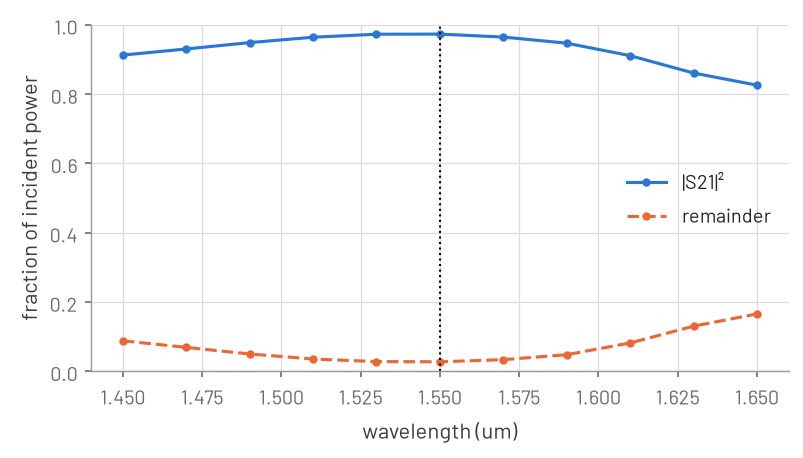

In [13]:
fig, ax = plt.subplots(figsize=(6, 3))
ax.plot(in_um, t_band, marker="o", ms=3, label="|S21|²")
ax.plot(in_um, remainder_band, ls="--", marker="o", ms=3, label="remainder")
ax.axvline(settings["wavelength_um"], color="k", ls=":", lw=1)
ax.set_ylim(0, 1)
ax.set_xlabel("wavelength (um)")
ax.set_ylabel("fraction of incident power")
ax.legend(loc="center right");

## Trust: the mirror, the mesh and the box

Re-solves of `final` at 1.55 µm, each read as ΔT, a change in |S21|². The mirror and
the box are compared on a check mesh coarser than the optimization's, h = 0.1 µm,
where the full stack and the larger box fit a direct solve: one more solve of
`final` on the mirror half model at that cell is their reference.

- **The mirror.** The full stack at h = 0.1 µm, with no PMC: twice the volume, in
  its own process. Its S-matrix should equal the mirror half model's to the
  solver's precision.
- **The box.** A 7 µm × 7 µm box (`box=3.5`) at h = 0.1 µm: the absorbing
  boundary 2 µm from the design in plane instead of 1 µm. Inside the 5 µm box the
  mesh is the same node for node, so the same pixels apply.
- **The mesh.** `final` on the mirror half model at three in-plane cells: the check
  mesh (0.1 µm), the optimization's and a finer one, 0.06 µm. Each mesh samples
  the pixels afresh, so a change of mesh moves the material and the field together.
  Fitting T(h) = T₀ + C hᵖ through the three points gives an observed order p and
  an extrapolated T₀; T(h) - T₀ at the optimization's h is the mesh error quoted
  for this design.
- **Eroded and dilated.** `design.robust` projects the filtered last iterate at
  thresholds 0.6, 0.5 and 0.4 (β = 64, δ = 0.1), as an over- or under-etch would
  thin or widen every core strip. These are projected densities, so they are read
  against the robust nominal's |S21|², not against `final`'s.

In [14]:
def observed_order(h, t):
    # T(h) = T0 + C h^p through three points of decreasing h: (p, T0), or None
    # when the cells repeat, the changes differ in sign, or no p in [0.5, 10] fits.
    (h1, h2, h3), (t1, t2, t3) = h, t
    if not h1 > h2 > h3 or (t1 - t2) * (t2 - t3) <= 0:
        return None
    ratio = (t1 - t2) / (t2 - t3)

    def excess(p):  # increases with p
        return (h1**p - h2**p) / (h2**p - h3**p) - ratio

    lo, hi = 0.5, 10.0
    if excess(lo) > 0 or excess(hi) < 0:
        return None
    for _ in range(60):  # bisection
        lo, hi = (
            (lo, (lo + hi) / 2) if excess((lo + hi) / 2) > 0 else ((lo + hi) / 2, hi)
        )
    p = (lo + hi) / 2
    return p, t3 - (t2 - t3) / (h2**p - h3**p) * h3**p


def stage_cost(stage):
    resources = observed[stage]
    return (
        f"{stage} stage {resources['wall_s'] / 60:.1f} min, "
        f"peak {resources['peak_rss_bytes'] / 2**30:.1f} GiB"
    )


solvers = {options["linear_solver"] for options in settings["solver_options"].values()}
print(f"every stage solves with: {', '.join(sorted(solvers))}")
t_check, check_on = transmission("s_final_h01"), mesh_entry(H["h_check"])
print(
    f"reference: final, mirror half model, h = {H['h_check']} um, "
    f"{check_on['dof']:,} DOF: |S21|^2 = {t_check:.4f}"
)
box7 = geometry["box_7um_half_width_um"]
for name, key, entry, stage in (
    ("full stack", "s_final_full", mesh_entry(H["h_check"], half=False), "full"),
    (f"{2 * box7:g} um box", "s_final_box7", mesh_entry(H["h_check"], box=box7), "box"),
):
    t = transmission(key)
    print(
        f"{name}: h = {entry['h_um']} um, {entry['dof']:,} DOF, |S21|^2 = {t:.4f}, "
        f"delta T = {t - t_check:+.1e} ({stage_cost(stage)})"
    )
print(
    "full stack against mirror half model: max |delta S| = "
    f"{np.abs(out['s_final_full'] - out['s_final_h01']).max():.1e}"
)

points = sorted(
    ((H["h_check"], "s_final_h01"), (H["h"], "s_final"), (H["h_fine"], "s_final_fine")),
    reverse=True,
)
print(
    f"final on three meshes, mirror half model ({stage_cost('fine')} for the finest):"
)
for h, key in points:
    print(
        f"  h = {h} um, {mesh_entry(h)['dof']:,} DOF: |S21|^2 = {transmission(key):.6f}"
    )
fit = observed_order([h for h, _ in points], [transmission(key) for _, key in points])
t_fine = transmission("s_final_fine")
if fit is None:
    mesh_error = abs(t_final - t_fine)
    print(
        "  no order p fits these points; the quoted mesh error is the change from "
        f"h = {H['h']} to {H['h_fine']} um, not extrapolated: {mesh_error:.1e}"
    )
else:
    p, t_limit = fit
    mesh_error = abs(t_final - t_limit)
    print(
        f"  observed order p = {p:.2f}, extrapolated T0 = {t_limit:.6f}; quoted mesh "
        f"error at h = {H['h']} um: |T(h) - T0| = {mesh_error:.1e}"
    )

robust = settings["robust"]
print(
    f"robust: beta = {robust['beta']:g}, thresholds 0.5 + {robust['delta']:g}, 0.5, "
    f"0.5 - {robust['delta']:g}"
)
t_eroded = report("eroded", "s_eroded")
t_nominal = report("robust nominal", "s_nominal")
t_dilated = report("dilated", "s_dilated")

every stage solves with: direct
reference: final, mirror half model, h = 0.1 um, 1,024,814 DOF: |S21|^2 = 0.9695
full stack: h = 0.1 um, 2,023,414 DOF, |S21|^2 = 0.9695, delta T = -7.2e-14 (full stage 3.4 min, peak 48.9 GiB)
7 um box: h = 0.1 um, 1,980,494 DOF, |S21|^2 = 0.9689, delta T = -6.6e-04 (box stage 1.5 min, peak 38.8 GiB)
full stack against mirror half model: max |delta S| = 2.0e-13
final on three meshes, mirror half model (fine stage 4.2 min, peak 78.1 GiB for the finest):
  h = 0.1 um, 1,024,814 DOF: |S21|^2 = 0.969519
  h = 0.07 um, 2,489,174 DOF: |S21|^2 = 0.972617
  h = 0.06 um, 3,548,406 DOF: |S21|^2 = 0.972910
  observed order p = 5.47, extrapolated T0 = 0.973131; quoted mesh error at h = 0.07 um: |T(h) - T0| = 5.1e-04
robust: beta = 64, thresholds 0.5 + 0.1, 0.5, 0.5 - 0.1
eroded: |S21|^2 = 0.7843 (1.055 dB), |S11|^2 = 3.6e-03, remainder = 0.2122
robust nominal: |S21|^2 = 0.9730 (0.119 dB), |S11|^2 = 5.0e-04, remainder = 0.0265
dilated: |S21|^2 = 0.8549 (0.681 dB), |S

The full stack moves |S21|² by -7.2 × 10⁻¹⁴ and the S-matrix by at most
2.0 × 10⁻¹³: the mirror half model gives the full stack's answer to the solver's
precision. The 7 µm × 7 µm box moves |S21|² by -6.6 × 10⁻⁴.

On the three meshes |S21|² is 0.969519, 0.972617 and 0.972910 as the cell shrinks
from 0.1 to 0.06 µm. The fit gives an observed order p = 5.47 and puts the error at
h = 0.07 µm at 5.1 × 10⁻⁴. Three points fix p and T₀ with nothing left over to test
the fit, so this is an estimate of the mesh error's size, not a bound. The box
moves |S21|² by more than that: at this level the absorbing boundary matters as
much as the mesh. Both stay well below the remainder, 0.0270, that the design
itself leaves.

The eroded and dilated designs transmit 0.7843 and 0.8549, against 0.9730 for the
robust nominal. An etch error of this size costs more than every model error above
together, and more than `final` loses at its design point: the pattern is
sensitive to fabrication, and the run did not optimize for that (Limits).

## The fields

|E| with 1 W incident in the fundamental mode at p1, for the arc design and for
`final`. Top row, the core mid-plane z = 0; the blue line is the core edge
(ρ = 0.5). Bottom row, the cross-section of the output guide between the design
square and port 2, mirrored to the full height, where power radiated out of the
plane shows above and below the guide, and a TE1-like part, odd across the guide,
makes |E| lopsided about x = 0; the blue rectangle is the core. Each design's maps
are scaled to its peak |E| in the input guide's part of the mid-plane, on one grey
scale. They are amplitudes, the square root of a power, so weak radiation shows
more strongly than its share of the power.

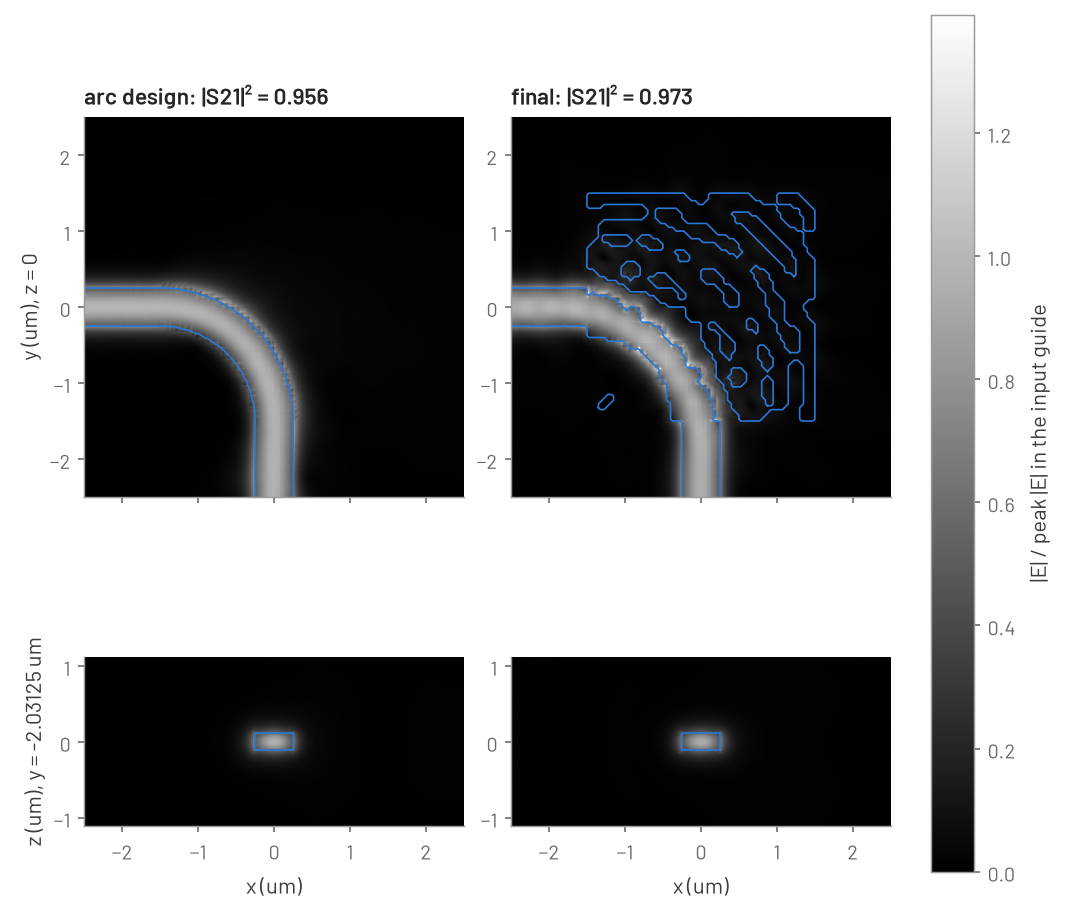

In [15]:
designs = {
    f"arc design: |S21|² = {t_arc:.3f}": ("arc", out["arc"]),
    f"final: |S21|² = {t_final:.3f}": ("final", final),
}
maps = {
    title: (
        density,
        out[f"cut_top_{name}"].astype(float) / input_peak[name],
        mirrored(out[f"cut_out_{name}"]).T / input_peak[name],
    )
    for title, (name, density) in designs.items()
}
vmax = max(max(mid.max(), cross.max()) for _, mid, cross in maps.values())
fig, axes = plt.subplots(
    2,
    2,
    figsize=(7, 6),
    sharex=True,
    height_ratios=[2 * HALF, 2 * Z_TOP],
    layout="constrained",
)
for (top_ax, cross_ax), (title, (density, mid, cross)) in zip(
    axes.T, maps.items(), strict=True
):
    image = top_ax.imshow(
        mid, origin="lower", extent=EXTENT, cmap="gray", vmin=0, vmax=vmax
    )
    for line in contour_generator(centres, centres, layer_image(density)).lines(0.5):
        top_ax.plot(*line.T, color="C0", ls="-", lw=0.8)
    top_ax.set_title(title)
    cross_ax.imshow(
        cross,
        origin="lower",
        extent=[-HALF, HALF, -Z_TOP, Z_TOP],
        cmap="gray",
        vmin=0,
        vmax=vmax,
    )
    cross_ax.plot(*(square * [GUIDE, CORE_HALF]).T, color="C0", ls="-", lw=0.8)
    cross_ax.set_xlabel("x (um)")
    for ax in (top_ax, cross_ax):
        ax.grid(False)
axes[0, 0].set_ylabel("y (um), z = 0")
axes[1, 0].set_ylabel(f"z (um), y = {cuts['cut_out_y_um']:g} um")
fig.colorbar(image, ax=axes, label="|E| / peak |E| in the input guide");

In both designs the field turns with the silicon and stays in it: the 0.5 µm
guide holds the mode through the turn. In `final` it follows the curved guide
along the inner side of the bend; the strips and islands outside carry little
field on this scale, so whatever they do acts on the small part of the field
outside the guide. In the output guide's cross-section both fields sit in the
core, with no radiation visible above or below and no visible lopsidedness: the
TE1-like powers, 0.0209 for the arc and 0.0041 for `final`, and the out-of-plane
share, 0.0130, are too small to show on this grey scale.

## Against the 2D bend

The two tutorials pose different problems, so their numbers are not compared here;
the [2D tutorial](bend.ipynb) gives its own. The recipe is the same; the guides
are not.

- The 2D slab model solves a TM problem, its electric field normal to the plane,
  and takes 2.25 for its core against 1.444 for its cladding, effective indices
  that stand for a stack. Its 0.55 µm guides also carry a second mode.
- This stack's mode is TE-like, and its indices are the materials' own, 3.476 and
  1.444. A core 0.22 µm thick holds the mode at n_eff = 2.445064, with a field
  that falls by 1/e every 0.125 µm into the oxide. Its 0.5 µm guides
  also carry a second TE-like mode, weakly guided.

In words: both designs turn nearly all of the power; this one must also keep it
out of the guide's second mode and in the plane of the chip. The 2D
design does not fit these guides, so it is not re-solved here.

## Against the paper

Irfan, Kim and Kurt (Sci. Rep. 14 (2024),
[PMC10948862](https://pmc.ncbi.nlm.nih.gov/articles/PMC10948862/)) optimize the
same bend on the same platform: a 0.5 µm guide in 220 nm silicon, the fundamental
TE-like mode, 3D topology optimization. For their 2.5 µm × 2.5 µm L-bend they
report a simulated loss of 0.07 dB in the abstract and below 0.06 dB in their
Table 1, from their own solver with indices 3.47 and 1.44. Their numbers are cited
here, not recomputed. Beside them, `final`'s loss, -10 log₁₀ |S21|², at 1.55 µm and
at its worst over the band, with the quoted mesh error in dB:

In [16]:
print(
    f"final: {decibels(t_final):.3f} dB at {settings['wavelength_um']} um, "
    f"at most {decibels(t_band).max():.3f} dB over {in_um[0]:g}-{in_um[-1]:g} um"
)
print(
    f"quoted mesh error: |S21|^2 within {mesh_error:.1e}, "
    f"{10 / np.log(10) * mesh_error / t_final:.3f} dB"
)
print(f"arc design: {decibels(t_arc):.3f} dB at {settings['wavelength_um']} um")

final: 0.121 dB at 1.55 um, at most 0.834 dB over 1.45-1.65 um
quoted mesh error: |S21|^2 within 5.1e-04, 0.002 dB
arc design: 0.195 dB at 1.55 um


`final` loses 0.121 dB at 1.55 µm, between the paper's 0.07 dB and the arc's
0.195 dB, and above the paper's by far more than the quoted mesh error of
0.002 dB; over the band it loses up to 0.834 dB. The setups differ in four ways,
each of which moves the comparison:

- **The square.** 3 µm × 3 µm here against their 2.5 µm × 2.5 µm. A larger square
  holds every pattern of the smaller one, so it can do at least as well; the sizes
  are not like for like.
- **The indices.** 3.4757 and 1.444024 here, from Li and Malitson, against their
  3.47 and 1.44, given without a source: 0.2 % apart in silicon.
- **The filter.** A Helmholtz filter of radius 0.2 µm with no minimum-width
  constraint here; theirs has a radius of 100 nm and enforces a 150 nm minimum
  feature through a penalty in the objective.
- **The objective.** |S21|² of the wave port's fundamental mode here; theirs is the
  overlap of the output field with the fundamental TE-like mode, the same quantity
  computed another way, plus that penalty. Their solver and mesh are their own.

## Limits

- **Not run in CI.** The numbers come from one run of `tools/bend3d_run.py` at the
  gfem commit and on the machine printed at the top; the page re-reads them and
  solves nothing. A change to the script or its mesh builder stops the page (the
  hash check), and a rerun costs about 2.7 h and $4.1 on 16 cores and 96 GiB; a
  change to gfem does not, so the numbers are those of gfem at that commit.
- **No substrate.** The oxide is 1.0 µm above and below the core, with no silicon
  under it. On a wafer with a 2 µm buried oxide, the mode's field at the silicon
  handle is about 10⁻⁷ of its value at the core (printed in "The
  stack"): an estimate from the decay length, not a solve with a substrate.
- **An absorbing boundary, not a PML.** A second-order absorbing boundary 1 µm from
  the design in plane and 1.0 µm from the core vertically. The straight guide loses
  1.8 × 10⁻⁴ over 5 µm with no bend; the 7 µm × 7 µm box moves |S21|² by
  -6.6 × 10⁻⁴, for this design only. The 1.0 µm from the core to the top and bottom
  faces is not varied.
- **The mesh is part of the material model.** Each element takes the pixel image
  at its centroid, so every re-solve changes the sampling and the field together.
  The fit through h = 0.1, 0.07 and 0.06 µm puts the error of |S21|² at
  h = 0.07 µm at 5.1 × 10⁻⁴, at 1.55 µm only.
- **Constant indices.** The indices are those at 1.55 µm, and the spectrum ignores
  their dispersion: over the band Si runs from 3.4845 to 3.4684 (Li's table) and
  SiO2 from 1.4452 to 1.4428 (Malitson's formula, printed in "The stack").
  Lossless media.
- **A symmetric, ideal stack.** The mirror half model imposes z symmetry: vertical
  sidewalls, a full etch, the same oxide above and below, and a design uniform
  through the core. A fabricated asymmetry would couple the TE-like modes to
  TM-like ones, which this model cannot represent.
- **One wavelength and a filter length scale.** The objective is |S21|² at
  1.55 µm, from one gradient run started at a uniform 0.5: it is the design this run
  found, not a bound. The spectrum is evaluated, not optimized. The 0.2 µm filter
  gives a length scale but no minimum width, and the paper's 150 nm minimum feature
  is not enforced; the eroded and dilated designs transmit 0.7843 and
  0.8549, against 0.9730 for the robust nominal.
- **The TE1-like mode is guided at 0.5 µm.** The wave ports solve the fundamental
  mode only, so a TE1-like wave reaching port 2 is partly reflected back into the
  design: about 3 % of its power, from a mode-overlap fit on the arc design outside
  this run. The printed TE1-like powers, 0.0041 for `final` and 0.0209
  for the arc, bound that effect.
- **The out-of-plane split and the TE1-like power are estimates.** They come from
  sampled-field fluxes: P_in differs from 1 - |S11|² by -1.8 × 10⁻² W, against
  an out-of-plane share of 0.0130 and a TE1-like power of 0.0041: the check's
  error is larger than the parts it splits.
- **2D and 3D are not like for like, and neither is the paper's setup.** The
  polarization, the indices and the guide width differ from the 2D tutorial's; the
  square, the indices, the filter and the objective from the paper's. The page
  compares them in words and cited numbers, not in re-solved ones.

## Next

- [The 2D bend tutorial](bend.ipynb): the same recipe, run end to end in its
  notebook.
- [Measurements](../recipes/measurements.md): `Field.at` and `Field.b()`, the
  point values behind the field cuts and the flux measurements.
- [S-parameter gradients](../recipes/s-parameter-gradient.md): what is
  differentiable in a driven solve.
- `tools/bend3d_run.py`: the run itself. `just bend3d-data` reruns every stage and
  rewrites the run record, about 2.7 h on 16 cores and 96 GiB with the `mkl` extra
  (`uv run --extra mkl --group docs`); `--profile smoke` runs the same stages on
  coarse meshes in minutes, for development.